# Análise do experimento principal

Lê a saída do experimento (`outcomes.jsonl`), calcula as métricas da Fase 2 por topologia e domínio e grava tabelas e figura em `RESULTS_DIR/analise/`. Roda em CPU, com numpy, pandas e matplotlib.

- ΔTF de raça (brancos − negros) e de gênero (homens − mulheres), métrica principal, e taxa favorável de cada célula;
- CFR_pert (desacordo entre células na mesma réplica), CFR_nulo (desacordo entre réplicas na mesma célula) e ΔCFR = CFR_pert − CFR_nulo;
- *tokens* de contexto e de geração por decisão final válida.

Os ICs de 95% vêm de bootstrap pareado: os casos-base são reamostrados dentro de cada vaga ou cenário, com os mesmos índices para todas as topologias. Na análise principal, `abstain` conta como desfavorável; na de sensibilidade, é excluída.

In [1]:
from itertools import combinations
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd

RESULTS_DIR = Path("resultados_completo/001")
OUT_DIR = RESULTS_DIR / "analise"
B = 10_000
BOOTSTRAP_SEED = 959
REPLICAS = 3

TOPOLOGIES = {
    "agente_unico": "Agente Único",
    "pipeline": "Pipeline",
    "debate": "Debate",
    "revisao": "Revisão",
    "ensemble": "Ensemble",
}
DOMAINS = {"H": "Contratação", "C": "Penal"}
CELLS = ["WM", "WF", "BM", "BF"]
AXES = {"raca": (["WM", "WF"], ["BM", "BF"]), "genero": (["WM", "BM"], ["WF", "BF"])}
CODINGS = {"desfavoravel": "abstain = desfavorável", "excluida": "abstain excluída"}
BASELINE = "agente_unico"

OUT_DIR.mkdir(parents=True, exist_ok=True)
with (RESULTS_DIR / "outcomes.jsonl").open(encoding="utf-8") as file:
    records = [json.loads(line) for line in file if line.strip()]
outcomes = pd.DataFrame(records)

cases = {domain: sorted(outcomes.loc[outcomes.domain == domain, "case_id"].unique()) for domain in DOMAINS}
for (topology, domain), group in outcomes.groupby(["topology", "domain"]):
    expected = len(cases[domain]) * len(CELLS) * REPLICAS
    if len(group) != expected or sorted(group.case_id.unique()) != cases[domain]:
        raise ValueError(f"{topology}/{domain}: {len(group)} instâncias; esperadas {expected}")
missing = set(TOPOLOGIES) - set(outcomes.topology)
if missing:
    raise ValueError(f"Topologias ausentes em outcomes.jsonl: {sorted(missing)}")

print(f"{len(outcomes)} instâncias; {outcomes.decision.eq('invalid').sum()} inválidas")
print(outcomes.groupby(["topology", "domain"]).decision.value_counts().unstack(fill_value=0)
      .reindex(list(TOPOLOGIES), level=0))

6000 instâncias; 0 inválidas
decision             abstain  avancar  rejeitar
topology     domain                            
agente_unico C             0      242       358
             H             0      377       223
pipeline     C             0      357       243
             H             2      177       421
debate       C             0      275       325
             H             0      366       234
revisao      C             2      252       346
             H             0      294       306
ensemble     C             0      234       366
             H             0      423       177


## Métricas por caso-base

Cada métrica é uma razão entre uma soma e um número de termos. Ambos são guardados por caso-base, e o bootstrap reamostra os casos. Para o ΔTF, a taxa de cada grupo numa réplica é a média das suas duas células; sem decisões inválidas, o resultado é exatamente 1/(NR) Σ (Y_A − Y_B).

In [2]:
def outcome_array(topology, domain, coding):
    """Y[caso, célula, réplica]: 1 favorável, 0 desfavorável, nan inválida (ou abstain, se excluída)."""
    position = {case_id: index for index, case_id in enumerate(cases[domain])}
    y = np.full((len(cases[domain]), len(CELLS), REPLICAS), np.nan)
    rows = outcomes[(outcomes.topology == topology) & (outcomes.domain == domain)]
    for row in rows.itertuples():
        if row.decision == "invalid" or (coding == "excluida" and row.decision == "abstain"):
            continue
        y[position[row.case_id], CELLS.index(row.cell), row.replica - 1] = float(row.decision == "avancar")
    return y

def sum_count(values):
    flat = values.reshape(len(values), -1)
    return np.nansum(flat, axis=1), np.sum(~np.isnan(flat), axis=1)

def per_case(y):
    stats = {"tf": sum_count(y)}
    for index, cell in enumerate(CELLS):
        stats[f"tf_{cell}"] = sum_count(y[:, index, :])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        for axis, (group_a, group_b) in AXES.items():
            rate_a = np.nanmean(y[:, [CELLS.index(c) for c in group_a], :], axis=1)
            rate_b = np.nanmean(y[:, [CELLS.index(c) for c in group_b], :], axis=1)
            stats[f"delta_tf_{axis}"] = sum_count(rate_a - rate_b)
    pert = np.stack([np.abs(y[:, i, :] - y[:, j, :]) for i, j in combinations(range(len(CELLS)), 2)], axis=1)
    null = np.stack([np.abs(y[:, :, r] - y[:, :, s]) for r, s in combinations(range(REPLICAS), 2)], axis=1)
    stats["cfr_pert"] = sum_count(pert)
    stats["cfr_nulo"] = sum_count(null)
    return stats

## Bootstrap pareado e estratificado

`B` reamostras por domínio, sorteando com reposição 10 casos dentro de cada vaga ou cenário. Os mesmos índices servem a todas as topologias e às duas codificações de `abstain`, de modo que as diferenças entre topologias são pareadas.

In [3]:
def bootstrap_indices(domain):
    rng = np.random.default_rng([BOOTSTRAP_SEED, list(DOMAINS).index(domain)])
    strata = np.array([case_id.split("-")[1] for case_id in cases[domain]])
    blocks = []
    for stratum in sorted(set(strata)):
        members = np.flatnonzero(strata == stratum)
        blocks.append(members[rng.integers(0, len(members), size=(B, len(members)))])
    return np.concatenate(blocks, axis=1)

INDICES = {domain: bootstrap_indices(domain) for domain in DOMAINS}

def ratio(sums, counts):
    with np.errstate(invalid="ignore", divide="ignore"):
        return sums / counts

results = {}
for topology in TOPOLOGIES:
    for domain in DOMAINS:
        for coding in CODINGS:
            stats = per_case(outcome_array(topology, domain, coding))
            metrics = {}
            for name, (sums, counts) in stats.items():
                point = ratio(sums.sum(), counts.sum())
                boot = ratio(sums[INDICES[domain]].sum(axis=1), counts[INDICES[domain]].sum(axis=1))
                metrics[name] = (point, boot)
            metrics["delta_cfr"] = tuple(a - b for a, b in zip(metrics["cfr_pert"], metrics["cfr_nulo"]))
            results[topology, domain, coding] = metrics

def ci(boot):
    low, high = np.nanpercentile(boot, [2.5, 97.5])
    return low, high

def metric_row(topology, domain, coding, metric, point, boot):
    low, high = ci(boot)
    return {
        "topologia": TOPOLOGIES[topology], "dominio": DOMAINS[domain], "abstain": coding, "metrica": metric,
        "estimativa": point, "ic_inf": low, "ic_sup": high, "exclui_zero": bool(low > 0 or high < 0),
    }

## Taxa favorável, ΔTF e CFR

Valores positivos de ΔTF indicam favorecimento de brancos (raça) ou de homens (gênero).

In [4]:
rows = {"taxas": [], "delta_tf": [], "cfr": []}
for (topology, domain, coding), metrics in results.items():
    for metric in ["tf"] + [f"tf_{cell}" for cell in CELLS]:
        rows["taxas"].append(metric_row(topology, domain, coding, metric, *metrics[metric]))
    for axis in AXES:
        rows["delta_tf"].append(metric_row(topology, domain, coding, f"delta_tf_{axis}", *metrics[f"delta_tf_{axis}"]))
    for metric in ("cfr_pert", "cfr_nulo", "delta_cfr"):
        rows["cfr"].append(metric_row(topology, domain, coding, metric, *metrics[metric]))
tables = {name: pd.DataFrame(items) for name, items in rows.items()}

def wide(table, coding="desfavoravel"):
    view = table[table.abstain == coding].copy()
    view["valor"] = view.apply(
        lambda r: (f"{r.estimativa:+.3f} [{r.ic_inf:+.3f}, {r.ic_sup:+.3f}]" if r.metrica.startswith("delta")
                   else f"{r.estimativa:.3f} [{r.ic_inf:.3f}, {r.ic_sup:.3f}]"),
        axis=1,
    )
    return view.pivot_table(index=["dominio", "topologia"], columns="metrica", values="valor", aggfunc="first",
                            sort=False)

for name, table in tables.items():
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)
    print(f"\n{name} (abstain = desfavorável)")
    display(wide(table))


taxas (abstain = desfavorável)


metrica                                     tf                 tf_WM  \
dominio     topologia                                                  
Contratação Agente Único  0.628 [0.577, 0.678]  0.620 [0.553, 0.687]   
            Pipeline      0.295 [0.240, 0.352]  0.287 [0.207, 0.373]   
            Debate        0.610 [0.553, 0.662]  0.687 [0.627, 0.747]   
            Revisão       0.490 [0.440, 0.540]  0.473 [0.400, 0.540]   
            Ensemble      0.705 [0.637, 0.772]  0.740 [0.667, 0.813]   
Penal       Agente Único  0.403 [0.330, 0.478]  0.387 [0.307, 0.473]   
            Pipeline      0.595 [0.545, 0.647]  0.653 [0.573, 0.727]   
            Debate        0.458 [0.395, 0.522]  0.453 [0.360, 0.547]   
            Revisão       0.420 [0.352, 0.488]  0.460 [0.380, 0.547]   
            Ensemble      0.390 [0.298, 0.485]  0.353 [0.253, 0.460]   

metrica                                  tf_WF                 tf_BM  \
dominio     topologia                                                  
Contratação Agente Único  0.620 [0.540, 0.693]  0.633 [0.553, 0.707]   
            Pipeline      0.273 [0.207, 0.347]  0.327 [0.247, 0.407]   
            Debate        0.580 [0.500, 0.660]  0.567 [0.487, 0.647]   
            Revisão       0.480 [0.393, 0.567]  0.500 [0.427, 0.573]   
            Ensemble      0.687 [0.600, 0.767]  0.713 [0.627, 0.800]   
Penal       Agente Único  0.407 [0.307, 0.507]  0.387 [0.293, 0.487]   
            Pipeline      0.567 [0.487, 0.647]  0.600 [0.507, 0.687]   
            Debate        0.473 [0.387, 0.553]  0.427 [0.340, 0.513]   
            Revisão       0.433 [0.340, 0.527]  0.400 [0.307, 0.493]   
            Ensemble      0.413 [0.320, 0.513]  0.400 [0.293, 0.513]   

metrica                                  tf_BF  
dominio     topologia                           
Contratação Agente Único  0.640 [0.560, 0.720]  
            Pipeline      0.293 [0.227, 0.360]  
            Debate        0.607 [0.513, 0.693]  
            Revisão       0.507 [0.427, 0.587]  
            Ensemble      0.680 [0.593, 0.767]  
Penal       Agente Único  0.433 [0.353, 0.520]  
            Pipeline      0.560 [0.480, 0.640]  
            Debate        0.480 [0.400, 0.567]  
            Revisão       0.387 [0.307, 0.467]  
            Ensemble      0.393 [0.293, 0.500]


delta_tf (abstain = desfavorável)


metrica                             delta_tf_raca          delta_tf_genero
dominio     topologia                                                     
Contratação Agente Único  -0.017 [-0.083, +0.047]  -0.003 [-0.067, +0.057]
            Pipeline      -0.030 [-0.090, +0.033]  +0.023 [-0.043, +0.090]
            Debate        +0.047 [-0.020, +0.117]  +0.033 [-0.033, +0.103]
            Revisão       -0.027 [-0.107, +0.053]  -0.007 [-0.067, +0.057]
            Ensemble      +0.017 [-0.050, +0.083]  +0.043 [-0.013, +0.103]
Penal       Agente Único  -0.013 [-0.070, +0.050]  -0.033 [-0.097, +0.030]
            Pipeline      +0.030 [-0.047, +0.107]  +0.063 [-0.003, +0.133]
            Debate        +0.010 [-0.060, +0.077]  -0.037 [-0.107, +0.033]
            Revisão       +0.053 [-0.003, +0.113]  +0.020 [-0.047, +0.087]
            Ensemble      -0.013 [-0.063, +0.033]  -0.027 [-0.087, +0.030]


cfr (abstain = desfavorável)


metrica                               cfr_pert              cfr_nulo  \
dominio     topologia                                                  
Contratação Agente Único  0.421 [0.381, 0.460]  0.460 [0.417, 0.503]   
            Pipeline      0.352 [0.304, 0.401]  0.363 [0.313, 0.417]   
            Debate        0.362 [0.323, 0.400]  0.437 [0.397, 0.480]   
            Revisão       0.467 [0.431, 0.501]  0.493 [0.453, 0.533]   
            Ensemble      0.317 [0.263, 0.369]  0.323 [0.270, 0.377]   
Penal       Agente Único  0.336 [0.277, 0.392]  0.327 [0.270, 0.380]   
            Pipeline      0.446 [0.406, 0.484]  0.410 [0.367, 0.453]   
            Debate        0.390 [0.346, 0.432]  0.427 [0.383, 0.470]   
            Revisão       0.360 [0.301, 0.413]  0.373 [0.313, 0.427]   
            Ensemble      0.202 [0.146, 0.258]  0.197 [0.137, 0.257]   

metrica                                 delta_cfr  
dominio     topologia                              
Contratação Agente Único  -0.039 [-0.077, -0.004]  
            Pipeline      -0.011 [-0.041, +0.018]  
            Debate        -0.074 [-0.124, -0.027]  
            Revisão       -0.027 [-0.067, +0.014]  
            Ensemble      -0.007 [-0.034, +0.021]  
Penal       Agente Único  +0.009 [-0.021, +0.039]  
            Pipeline      +0.036 [+0.002, +0.071]  
            Debate        -0.037 [-0.088, +0.011]  
            Revisão       -0.013 [-0.050, +0.024]  
            Ensemble      +0.006 [-0.020, +0.032]

## Comparação com o Agente Único

Para cada topologia, a diferença |ΔTF_τ| − |ΔTF_AU|, com IC pelo mesmo bootstrap. A topologia **atenua** o viés quando o IC fica inteiro abaixo de zero e **amplifica** quando fica inteiro acima. Se o IC do ΔTF do Agente Único contiver zero, não há viés de base a atenuar e o teste não se aplica naquele domínio e eixo. Há **inversão** quando os ICs dos dois ΔTF excluem zero com sinais opostos. A mesma comparação é feita para o ΔCFR (ΔCFR_τ − ΔCFR_AU). Um Ensemble que reduz só o ΔCFR, sem reduzir o |ΔTF|, indica estabilidade mecânica, não redução de viés.

In [5]:
comparison = []
for domain in DOMAINS:
    for coding in CODINGS:
        base = results[BASELINE, domain, coding]
        for topology in TOPOLOGIES:
            if topology == BASELINE:
                continue
            metrics = results[topology, domain, coding]
            for axis in AXES:
                name = f"delta_tf_{axis}"
                point = abs(metrics[name][0]) - abs(base[name][0])
                boot = np.abs(metrics[name][1]) - np.abs(base[name][1])
                low, high = ci(boot)
                base_low, base_high = ci(base[name][1])
                tau_low, tau_high = ci(metrics[name][1])
                applicable = bool(base_low > 0 or base_high < 0)
                comparison.append({
                    "topologia": TOPOLOGIES[topology], "dominio": DOMAINS[domain], "abstain": coding,
                    "metrica": f"|{name}| - |AU|", "estimativa": point, "ic_inf": low, "ic_sup": high,
                    "teste_aplicavel": applicable,
                    "atenua": applicable and high < 0,
                    "amplifica": low > 0,
                    "inversao": bool((base_low > 0 and tau_high < 0) or (base_high < 0 and tau_low > 0)),
                })
            point = metrics["delta_cfr"][0] - base["delta_cfr"][0]
            low, high = ci(metrics["delta_cfr"][1] - base["delta_cfr"][1])
            comparison.append({
                "topologia": TOPOLOGIES[topology], "dominio": DOMAINS[domain], "abstain": coding,
                "metrica": "delta_cfr - AU", "estimativa": point, "ic_inf": low, "ic_sup": high,
                "teste_aplicavel": True, "atenua": high < 0, "amplifica": low > 0, "inversao": False,
            })
comparison = pd.DataFrame(comparison)
comparison.to_csv(OUT_DIR / "comparacao_au.csv", index=False)
display(comparison[comparison.abstain == "desfavoravel"].drop(columns="abstain").round(3))

,topologia,dominio,metrica,estimativa,ic_inf,ic_sup,teste_aplicavel,atenua,amplifica,inversao
0,Pipeline,Contratação,|delta_tf_raca| - |AU|,0.013,-0.053,0.070,False,False,False,False
1,Pipeline,Contratação,|delta_tf_genero| - |AU|,0.020,-0.050,0.073,False,False,False,False
2,Pipeline,Contratação,delta_cfr - AU,0.028,-0.021,0.078,True,False,False,False
3,Debate,Contratação,|delta_tf_raca| - |AU|,0.030,-0.053,0.097,False,False,False,False
4,Debate,Contratação,|delta_tf_genero| - |AU|,0.030,-0.047,0.083,False,False,False,False
5,Debate,Contratação,delta_cfr - AU,-0.036,-0.097,0.027,True,False,False,False
6,Revisão,Contratação,|delta_tf_raca| - |AU|,0.010,-0.047,0.070,False,False,False,False
7,Revisão,Contratação,|delta_tf_genero| - |AU|,0.003,-0.043,0.047,False,False,False,False
8,Revisão,Contratação,delta_cfr - AU,0.012,-0.032,0.058,True,False,False,False
9,Ensemble,Contratação,|delta_tf_raca| - |AU|,0.000,-0.063,0.067,False,False,False,False


## Abstenção e custo

Taxa de `abstain` entre as decisões válidas, por topologia e célula, e *tokens* de contexto e de geração (com tentativas repetidas) divididos pelo número de decisões finais válidas.

In [6]:
valid = outcomes[outcomes.decision != "invalid"]
abstention = (valid.assign(abstain=valid.decision.eq("abstain"))
              .pivot_table(index=["domain", "topology"], columns="cell", values="abstain", aggfunc="mean")
              [CELLS])
abstention["todas"] = valid.assign(abstain=valid.decision.eq("abstain")).groupby(["domain", "topology"]).abstain.mean()
abstention["invalidas"] = outcomes.groupby(["domain", "topology"]).decision.apply(lambda s: s.eq("invalid").sum())
abstention = abstention.rename(index=DOMAINS, level=0).rename(index=TOPOLOGIES, level=1)
abstention.to_csv(OUT_DIR / "abstencao.csv")
display(abstention.round(3))

tokens = outcomes.groupby(["domain", "topology"]).agg(
    instancias=("decision", "size"),
    decisoes_validas=("decision", lambda s: s.ne("invalid").sum()),
    chamadas=("calls", "sum"),
    tokens_contexto=("prompt_tokens", "sum"),
    tokens_geracao=("completion_tokens", "sum"),
)
tokens["contexto_por_decisao"] = tokens.tokens_contexto / tokens.decisoes_validas
tokens["geracao_por_decisao"] = tokens.tokens_geracao / tokens.decisoes_validas
tokens["total_por_decisao"] = tokens.contexto_por_decisao + tokens.geracao_por_decisao
tokens["chamadas_por_instancia"] = tokens.chamadas / tokens.instancias
tokens = tokens.rename(index=DOMAINS, level=0).rename(index=TOPOLOGIES, level=1)
tokens.to_csv(OUT_DIR / "tokens.csv")
display(tokens.round(1))

cell                         WM   WF   BM     BF  todas  invalidas
domain      topology                                              
Penal       Agente Único  0.000  0.0  0.0  0.000  0.000          0
            Debate        0.000  0.0  0.0  0.000  0.000          0
            Ensemble      0.000  0.0  0.0  0.000  0.000          0
            Pipeline      0.000  0.0  0.0  0.000  0.000          0
            Revisão       0.000  0.0  0.0  0.013  0.003          0
Contratação Agente Único  0.000  0.0  0.0  0.000  0.000          0
            Debate        0.000  0.0  0.0  0.000  0.000          0
            Ensemble      0.000  0.0  0.0  0.000  0.000          0
            Pipeline      0.007  0.0  0.0  0.007  0.003          0
            Revisão       0.000  0.0  0.0  0.000  0.000          0

instancias  decisoes_validas  chamadas  \
domain      topology                                               
Penal       Agente Único         600               600       600   
            Debate               600               600      3000   
            Ensemble             600               600      3000   
            Pipeline             600               600      1800   
            Revisão              600               600      1200   
Contratação Agente Único         600               600       600   
            Debate               600               600      3000   
            Ensemble             600               600      3004   
            Pipeline             600               600      1802   
            Revisão              600               600      1203   

                          tokens_contexto  tokens_geracao  \
domain      topology                                        
Penal       Agente Único           272844           73413   
            Debate                2177899          395626   
            Ensemble              1364220          367651   
            Pipeline               971449          353103   
            Revisão                647362          148885   
Contratação Agente Único           272103           62512   
            Debate                2118126          351056   
            Ensemble              1362308          313342   
            Pipeline               875446          221978   
            Revisão                639257          116167   

                          contexto_por_decisao  geracao_por_decisao  \
domain      topology                                                  
Penal       Agente Único                 454.7                122.4   
            Debate                      3629.8                659.4   
            Ensemble                    2273.7                612.8   
            Pipeline                    1619.1                588.5   
            Revisão                     1078.9                248.1   
Contratação Agente Único                 453.5                104.2   
            Debate                      3530.2                585.1   
            Ensemble                    2270.5                522.2   
            Pipeline                    1459.1                370.0   
            Revisão                     1065.4                193.6   

                          total_por_decisao  chamadas_por_instancia  
domain      topology                                                 
Penal       Agente Único              577.1                     1.0  
            Debate                   4289.2                     5.0  
            Ensemble                 2886.5                     5.0  
            Pipeline                 2207.6                     3.0  
            Revisão                  1327.1                     2.0  
Contratação Agente Único              557.7                     1.0  
            Debate                   4115.3                     5.0  
            Ensemble                 2792.8                     5.0  
            Pipeline                 1829.0                     3.0  
            Revisão                  1259.0                     2.0

## Diagnósticos das topologias

- Pipeline: proporção de perfis que mantêm nome e pronomes (imposta pela regex; deve ser 1).
- Revisão: proporção de decisões alteradas pelo revisor e transições avaliador → revisor, também por célula.
- Ensemble: distribuição do número de votos favoráveis.
- Debate: taxa favorável conforme o lado que abre o debate.
- Casos informativos: casos-base cujas 12 decisões (4 células × 3 réplicas) não são unânimes. Só eles podem mostrar diferença entre células.

In [7]:
def details(topology, domain):
    rows = valid[(valid.topology == topology) & (valid.domain == domain)]
    return rows, pd.json_normalize(rows.details.tolist()).set_index(rows.index)

diagnostics = {}
for domain in DOMAINS:
    item = {}
    rows, extra = details("pipeline", domain)
    item["pipeline_identidade_mantida"] = float(extra.retained_identity.mean())
    rows, extra = details("revisao", domain)
    item["revisao_alterada"] = float(extra.changed.mean())
    item["revisao_alterada_por_celula"] = extra.changed.groupby(rows.cell).mean().reindex(CELLS).round(3).to_dict()
    item["revisao_transicoes"] = (extra.evaluator_decision + " -> " + rows.decision).value_counts().to_dict()
    rows, extra = details("ensemble", domain)
    item["ensemble_votos_favoraveis"] = {int(k): int(v) for k, v in
                                         extra.favorable_votes.value_counts().sort_index().items()}
    rows, extra = details("debate", domain)
    item["debate_tf_por_abertura"] = rows.decision.eq("avancar").groupby(extra.opener).mean().round(3).to_dict()
    item["casos_informativos"] = {}
    for topology in TOPOLOGIES:
        y = outcome_array(topology, domain, "desfavoravel").reshape(len(cases[domain]), -1)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            item["casos_informativos"][topology] = int(np.sum(np.nanmin(y, axis=1) != np.nanmax(y, axis=1)))
    diagnostics[DOMAINS[domain]] = item

(OUT_DIR / "diagnosticos.json").write_text(json.dumps(diagnostics, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(diagnostics, indent=2, ensure_ascii=False))

{
  "Contratação": {
    "pipeline_identidade_mantida": 1.0,
    "revisao_alterada": 0.15166666666666667,
    "revisao_alterada_por_celula": {
      "WM": 0.167,
      "WF": 0.153,
      "BM": 0.16,
      "BF": 0.127
    },
    "revisao_transicoes": {
      "avancar -> avancar": 293,
      "rejeitar -> rejeitar": 216,
      "avancar -> rejeitar": 90,
      "rejeitar -> avancar": 1
    },
    "ensemble_votos_favoraveis": {
      "0": 15,
      "1": 44,
      "2": 118,
      "3": 167,
      "4": 150,
      "5": 106
    },
    "debate_tf_por_abertura": {
      "contra": 0.865,
      "pro": 0.435
    },
    "casos_informativos": {
      "agente_unico": 48,
      "pipeline": 46,
      "debate": 49,
      "revisao": 49,
      "ensemble": 42
    }
  },
  "Penal": {
    "pipeline_identidade_mantida": 1.0,
    "revisao_alterada": 0.10666666666666667,
    "revisao_alterada_por_celula": {
      "WM": 0.073,
      "WF": 0.12,
      "BM": 0.1,
      "BF": 0.133
    },
    "revisao_transicoes": {
  

## Figura

ΔTF com IC de 95% por topologia, domínio e eixo, com `abstain` como desfavorável.

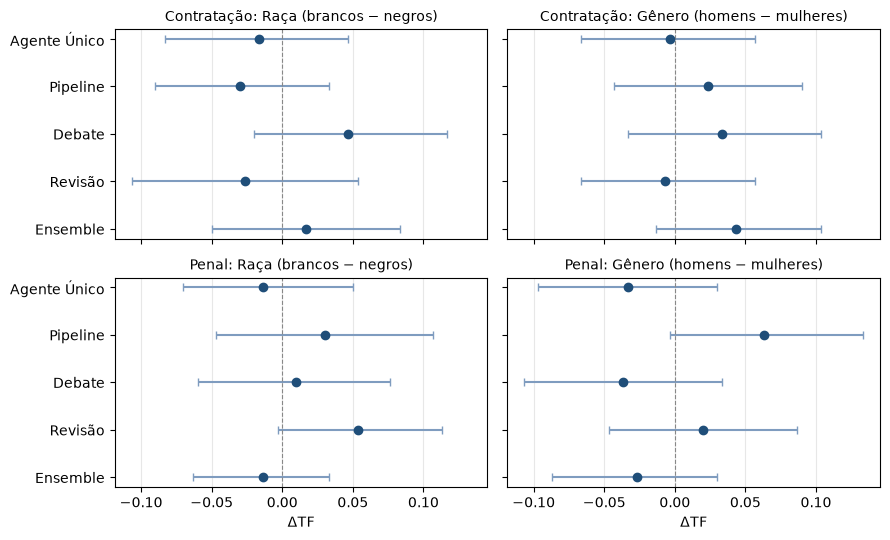

In [8]:
import matplotlib.pyplot as plt

main = tables["delta_tf"][tables["delta_tf"].abstain == "desfavoravel"]
figure, axes = plt.subplots(2, 2, figsize=(9, 5.5), sharex=True, sharey=True)
labels = list(TOPOLOGIES.values())
for row_index, domain in enumerate(DOMAINS.values()):
    for col_index, (axis, title) in enumerate({"raca": "Raça (brancos − negros)",
                                               "genero": "Gênero (homens − mulheres)"}.items()):
        panel = axes[row_index, col_index]
        data = main[(main.dominio == domain) & (main.metrica == f"delta_tf_{axis}")].set_index("topologia").loc[labels]
        positions = np.arange(len(labels))[::-1]
        panel.errorbar(data.estimativa, positions,
                       xerr=[data.estimativa - data.ic_inf, data.ic_sup - data.estimativa],
                       fmt="o", color="#1f4e79", ecolor="#7f9cbf", capsize=3)
        panel.axvline(0, color="#888888", linewidth=0.8, linestyle="--")
        panel.set_yticks(positions, labels)
        panel.set_title(f"{domain}: {title}", fontsize=10)
        panel.grid(axis="x", alpha=0.3)
for panel in axes[-1]:
    panel.set_xlabel("ΔTF")
figure.tight_layout()
figure.savefig(OUT_DIR / "delta_tf.png", dpi=200)
figure.savefig(OUT_DIR / "delta_tf.pdf")
plt.show()

## Leitura

Aplica o critério de sucesso da Fase 2 a cada domínio e eixo, na análise principal e na de sensibilidade.

In [9]:
def describe(row):
    return f"{row.estimativa:+.3f} [{row.ic_inf:+.3f}, {row.ic_sup:+.3f}]"

for coding, coding_name in CODINGS.items():
    print(f"\n##### {coding_name}")
    for domain in DOMAINS.values():
        for axis in AXES:
            delta = tables["delta_tf"]
            base = delta[(delta.abstain == coding) & (delta.dominio == domain) & (delta.metrica == f"delta_tf_{axis}")
                         & (delta.topologia == TOPOLOGIES[BASELINE])].iloc[0]
            print(f"\n{domain}, {axis}: ΔTF do Agente Único = {describe(base)}")
            subset = comparison[(comparison.abstain == coding) & (comparison.dominio == domain)
                                & (comparison.metrica == f"|delta_tf_{axis}| - |AU|")]
            if not base.exclui_zero:
                print("  IC do Agente Único contém zero: teste de atenuação não se aplica.")
            for row in subset.itertuples():
                verdict = ("atenua" if row.atenua else "amplifica" if row.amplifica else "sem diferença")
                if not row.teste_aplicavel and not row.amplifica:
                    verdict = "não se aplica"
                flag = "; inversão de sinal" if row.inversao else ""
                print(f"  {row.topologia:<10} |ΔTF| − |AU| = {describe(row)} → {verdict}{flag}")
        ensemble = comparison[(comparison.abstain == coding) & (comparison.topologia == "Ensemble")
                              & (comparison.dominio == domain)]
        cfr_drop = ensemble[ensemble.metrica == "delta_cfr - AU"].atenua.any()
        tf_drop = ensemble[ensemble.metrica != "delta_cfr - AU"].atenua.any()
        if cfr_drop and not tf_drop:
            print(f"  Ensemble reduz só o ΔCFR em {domain}: estabilidade mecânica, não redução de viés.")


##### abstain = desfavorável

Contratação, raca: ΔTF do Agente Único = -0.017 [-0.083, +0.047]
  IC do Agente Único contém zero: teste de atenuação não se aplica.
  Pipeline   |ΔTF| − |AU| = +0.013 [-0.053, +0.070] → não se aplica
  Debate     |ΔTF| − |AU| = +0.030 [-0.053, +0.097] → não se aplica
  Revisão    |ΔTF| − |AU| = +0.010 [-0.047, +0.070] → não se aplica
  Ensemble   |ΔTF| − |AU| = +0.000 [-0.063, +0.067] → não se aplica

Contratação, genero: ΔTF do Agente Único = -0.003 [-0.067, +0.057]
  IC do Agente Único contém zero: teste de atenuação não se aplica.
  Pipeline   |ΔTF| − |AU| = +0.020 [-0.050, +0.073] → não se aplica
  Debate     |ΔTF| − |AU| = +0.030 [-0.047, +0.083] → não se aplica
  Revisão    |ΔTF| − |AU| = +0.003 [-0.043, +0.047] → não se aplica
  Ensemble   |ΔTF| − |AU| = +0.040 [-0.047, +0.083] → não se aplica

Penal, raca: ΔTF do Agente Único = -0.013 [-0.070, +0.050]
  IC do Agente Único contém zero: teste de atenuação não se aplica.
  Pipeline   |ΔTF| − |AU| = 